In [4]:
%load_ext autoreload
%autoreload 2

In [21]:
# from prrt_clustering import correct_z_drift, detect_puncta, cluster_dbscan, pair_cluster, pair_puncta
import prrt_clustering as pclst
from pathlib import Path
from bioio import BioImage
import yaml

def run_checks(points, parameters):
    """Check that the number of PSD and RIM puncta is more than the min_samples."""
    min_samples = parameters["dbscan"]["min_samples"]
    n = (points.groupby(["synapse_id", "C"], dropna=False)[["cluster_id"]]
        .count()
        .pivot_table(index="synapse_id", columns="C", values="cluster_id")
        .loc[:,["PSD","RIM"]]
        .min(axis=1)<min_samples
    ).sum()
    if n > 0:
        print(f"Number of puncta in {n} synapse lower than {min_samples}.")

def process(data_path: Path, output_folder, parameters):
    """Process."""
    name = data_path.stem
    print(name)
    with open(output_folder / f"{name}_parameters.yaml", "w") as f:
        yaml.safe_dump(parameters, f)
    image = BioImage(data_path)
    data = image.xarray_dask_data.assign_coords({"C": parameters["channels"]})
    shift, stabilized = pclst.correct_z_drift(data)
    points = pclst.detect_puncta(stabilized[0], parameters["detection"])
    points, clusters = pclst.cluster_dbscan(points, **parameters["dbscan"])
    points, synapses = pclst.pair_cluster(
        points, ["PSD", "RIM"], **parameters["synapse"]
    )
    points, pairs = pclst.pair_puncta(points, ["A1", "PRRT"], **parameters["pairs"])
    points = pclst.associate_to_paired_cluster(points, **parameters["synapse"])
    points = pclst.compute_distances(points)
    run_checks(points, parameters)
    g_stats = pclst.global_stats(points, **parameters["synapse"])
    s_stats = pclst.synapse_stats(points)
    s_stats.to_csv(output_folder / f"{name}_s_stats.csv")
    points.to_csv(output_folder / f"{name}_points.csv")
    with open(output_folder / f"{name}_g_stats.yaml", "w") as f:
        yaml.safe_dump(g_stats, f)


In [22]:
parameters = {
    "channels": ["PRRT", "A1", "PSD", "RIM"],
    "detection": {
        "PRRT": {"scale_um": 0.4, "specificity": 6},
        "A1": {"scale_um": 0.3, "specificity": 6},
        "PSD": {"scale_um": 0.1, "specificity": 8},
        "RIM": {"scale_um": 0.1, "specificity": 6},
    },
    "dbscan": {"eps": 1., "min_samples": 3},
    "synapse": {"distance": 1},
    "pairs": {"distance": 0.5},
}

output_folder = Path("./results")

folder = [
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261006 Re-image",
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261016 Repeat",
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat",
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat",
]

for data_path in folder:
    for filename in Path(data_path).glob("**/*.czi"):
        try:
            process(filename, output_folder, parameters)
        except Exception:
            print("fail")
        

Re-image 261006 Experiment-134
Number of puncta in 1 synapse lower than 3.
Re-image 261006 Experiment-133
Number of puncta in 2 synapse lower than 3.
Re-image 261006 Experiment-132
Number of puncta in 1 synapse lower than 3.
Re-image 261006 Experiment-131
Number of puncta in 3 synapse lower than 3.
Re-image 261006 Experiment-129
fail
Re-image 261006 Experiment-127
Number of puncta in 29 synapse lower than 3.
Re-image 261006 Experiment-128
Number of puncta in 3 synapse lower than 3.
Experiment-300
Number of puncta in 1 synapse lower than 3.
Experiment-295
Number of puncta in 2 synapse lower than 3.
Experiment-294
Number of puncta in 7 synapse lower than 3.
Experiment-156
Number of puncta in 6 synapse lower than 3.
Experiment-157
Number of puncta in 6 synapse lower than 3.
Experiment-154
Number of puncta in 3 synapse lower than 3.
Experiment-153
Number of puncta in 1 synapse lower than 3.
Experiment-152
Number of puncta in 1 synapse lower than 3.
Experiment-155
Number of puncta in 2 syna

Reload all results

In [6]:
import pandas as pd

sst = pd.concat(
    [
        pd.read_csv(x, index_col=0).assign(file=x.stem)
        for x in output_folder.glob("*_s_stats.csv")
    ],
    ignore_index=True,
)
points = pd.concat(
    [
        pd.read_csv(x, index_col=0).assign(file=x.stem)
        for x in output_folder.glob("*_points.csv")
    ],
    ignore_index=True,
)


np.int64(107)

In [8]:
run_checks(points,parameters)

Number of puncta in some synapse lower than min_sample.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


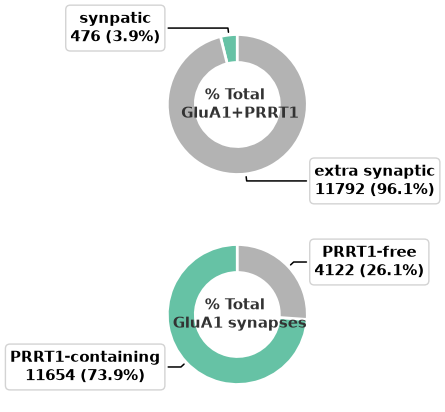

In [23]:
from prrt_clustering.plot import make_the_bagel_plot
import matplotlib.pyplot as plt

gst = []
for x in output_folder.glob("*_g_stats.yaml"):
    with open(x, "r") as f:
        gst.append(yaml.safe_load(f))
        gst[-1]["file"] = x.stem
gst = pd.DataFrame.from_records(gst)
gst.to_csv(output_folder/"global_stats.csv")


make_the_bagel_plot(gst.sum().to_dict(), sst)
plt.savefig(output_folder / "bagel.pdf")

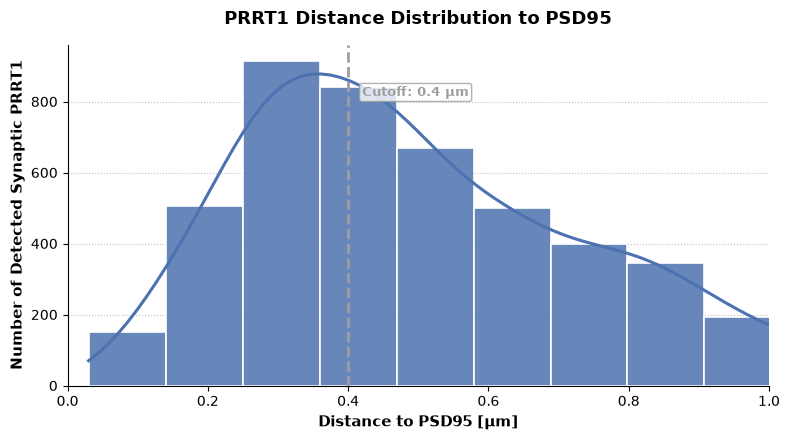

In [ ]:
from prrt_clustering.plot import make_the_histogram_distance

x = make_the_histogram_distance(points)

<Axes: xlabel='distance'>

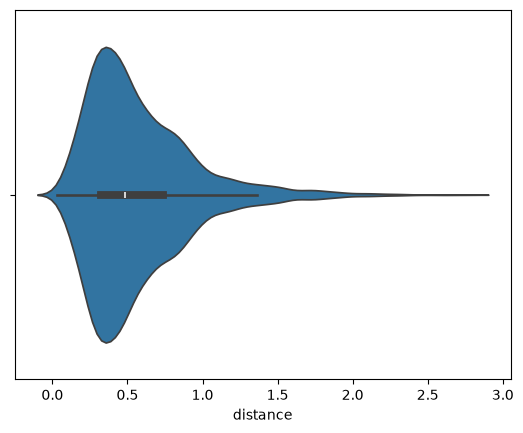

In [ ]:
import seaborn as sns

df = pd.DataFrame({"distance":x})
sns.violinplot(df,x="distance")
# sns.swarmplot(df,x="distance")

In [ ]:
df.to_csv("results/distance_prrt_psd.csv",index=False)

In [ ]:
import seaborn as sns

sns.catplot(
    gst.melt(id_vars="file"),
    y="file",
    x="value",
    col="variable",
    col_wrap=5,
    kind="bar",
    sharex=False,
).set_titles("{col_name}")